In [1]:
# Import PyTorch and torchvision libraries
from torchvision import datasets
import torchvision.transforms as transforms

# Import Dataset and DataLoader
from torch.utils.data import Dataset, DataLoader

# Import PyTorch
import torch
import torch.nn as nn

# Import numerical and visualization libraries
import numpy as np
import matplotlib.pyplot as plt

# Import dataset loading library
from datasets import load_dataset

# Import data splitting and evaluation utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from collections import Counter
import random
import os

%matplotlib inline

# Set random seed for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Select GPU if available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [2]:
# Load PlantVillage dataset from Hugging Face
ds = load_dataset("Project-AgML/plant_village_classification")

# Display dataset information
print("Dataset loaded successfully!")
print(ds)

# Access the original training split
original_data = ds["train"]

print("\nTotal Images:", len(original_data))
print("Dataset Features:", original_data.features)

README.md:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  431MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  432MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/55448 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 55448
    })
})

Total Images: 55448
Dataset Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___hea

In [3]:
# Import required transformations and splitting utilities
from torch.utils.data import random_split

# Set image resolution
size = 64

# Define training transformations with data augmentation
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

# Define validation and testing transformations
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Get original class names
class_names_all = original_data.features["label"].names

# Count images belonging to each class
labels_all = original_data["label"]
class_counts = Counter(labels_all)

# Select classes containing at least 400 images
eligible_classes = [
    i for i in range(len(class_names_all))
    if class_counts[i] >= 400
]

# Select 20 classes alphabetically
eligible_classes = sorted(
    eligible_classes,
    key=lambda i: class_names_all[i]
)

if len(eligible_classes) < 20:
    raise ValueError("Not enough classes with 400 images!")

selected_class_ids = eligible_classes[:20]

# Create a new mapping for the selected classes
class_to_idx = {
    original_id: new_id
    for new_id, original_id in enumerate(selected_class_ids)
}

selected_class_names = [
    class_names_all[i] for i in selected_class_ids
]

# Select exactly 400 images from each class
rng = np.random.default_rng(seed)

selected_indices = []

for class_id in selected_class_ids:

    class_indices = [
        i for i, label in enumerate(labels_all)
        if label == class_id
    ]

    sampled_indices = rng.choice(
        class_indices,
        size=400,
        replace=False
    )

    selected_indices.extend(sampled_indices.tolist())

# Shuffle selected image indices
rng.shuffle(selected_indices)

# Create selected 8,000-image dataset
selected_data = original_data.select(selected_indices)

# Create stratified 70/15/15 split
selected_labels = np.array(selected_data["label"])
all_indices = np.arange(len(selected_data))

train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=seed,
    stratify=selected_labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=seed,
    stratify=selected_labels[temp_indices]
)

# Custom Dataset compatible with the teacher's ImageFolder approach
class PlantVillageDataset(Dataset):

    def __init__(self, dataset, indices, transform):

        self.dataset = dataset
        self.indices = indices
        self.transform = transform

        # Preserve class names and class mapping
        self.classes = selected_class_names
        self.class_to_idx = {
            name: i for i, name in enumerate(self.classes)
        }

    def __getitem__(self, ix):

        # Get the original dataset index
        actual_index = self.indices[ix]

        sample = self.dataset[int(actual_index)]

        # Convert image into RGB format
        image = sample["image"].convert("RGB")

        # Convert original label to selected class index
        label = class_to_idx[sample["label"]]

        # Apply image transformation
        image = self.transform(image)

        return image, label

    def __len__(self):
        return len(self.indices)


# Create training, validation and testing datasets
train_data = PlantVillageDataset(
    selected_data,
    train_indices,
    train_transform
)

val_data = PlantVillageDataset(
    selected_data,
    val_indices,
    val_transform
)

test_data = PlantVillageDataset(
    selected_data,
    test_indices,
    val_transform
)

In [4]:
print("Dataset Summary")

print("Train Data:", len(train_data))
print("Validation Data:", len(val_data))
print("Test Data:", len(test_data))

print("\nClasses and Indices:")

print(train_data.class_to_idx)

print("\nSelected Class Names:")

for i, name in enumerate(train_data.classes):
    print(i, ":", name)

print("\nTotal Images:",
      len(train_data) + len(val_data) + len(test_data))

Dataset Summary
Train Data: 5600
Validation Data: 1200
Test Data: 1200

Classes and Indices:
{'Apple___Apple_scab': 0, 'Apple___Black_rot': 1, 'Apple___healthy': 2, 'Background_without_leaves': 3, 'Blueberry___healthy': 4, 'Cherry___Powdery_mildew': 5, 'Cherry___healthy': 6, 'Corn___Cercospora_leaf_spot Gray_leaf_spot': 7, 'Corn___Common_rust': 8, 'Corn___Northern_Leaf_Blight': 9, 'Corn___healthy': 10, 'Grape___Black_rot': 11, 'Grape___Esca_(Black_Measles)': 12, 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 13, 'Grape___healthy': 14, 'Orange___Haunglongbing_(Citrus_greening)': 15, 'Peach___Bacterial_spot': 16, 'Pepper,_bell___Bacterial_spot': 17, 'Pepper,_bell___healthy': 18, 'Potato___Early_blight': 19}

Selected Class Names:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___healthy
3 : Background_without_leaves
4 : Blueberry___healthy
5 : Cherry___Powdery_mildew
6 : Cherry___healthy
7 : Corn___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn___Common_rust
9 : Corn___Northern_Leaf_

In [5]:
# Define training hyperparameters

batch_size = 32

learning_rate = 1e-3

epoch_number = 20

print("Batch Size:", batch_size)
print("Learning Rate:", learning_rate)
print("Epoch Number:", epoch_number)

Batch Size: 32
Learning Rate: 0.001
Epoch Number: 20


In [6]:
# Create training DataLoader
trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device == "cuda")
)

# Create validation DataLoader
val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device == "cuda")
)

# Create testing DataLoader
test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device == "cuda")
)

print("Training Batches:", len(trn_dl))
print("Validation Batches:", len(val_dl))
print("Testing Batches:", len(test_dl))

Training Batches: 175
Validation Batches: 38
Testing Batches: 38


In [7]:
from torch.optim import SGD, Adam

def get_model():

    model = nn.Sequential(

        # Feature Extraction

        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier

        nn.Flatten(),

        nn.Linear(128 * 14 * 14, 256),

        nn.ReLU(),

        nn.Linear(256, 20)

    ).to(device)

    # Define loss function
    loss_fn = nn.CrossEntropyLoss()

    # Define optimizer
    optimizer = Adam(
        model.parameters(),
        lr=learning_rate
    )

    return model, loss_fn, optimizer

In [8]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):

    # Set model to training mode
    model.train()

    epoch_losses, epoch_accuracies = [], []

    for x, y in data_loader:

        # Move images and labels to GPU/CPU
        x, y = x.to(device), y.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        prediction = model(x)

        # Calculate loss
        batch_loss = loss_fn(prediction, y)

        # Backpropagation
        batch_loss.backward()

        # Update model parameters
        optimizer.step()

        epoch_losses.append(batch_loss.item())

        # Calculate batch accuracy
        is_correct = (prediction.argmax(-1) == y).cpu().tolist()

        epoch_accuracies.extend(is_correct)

    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):

    # Set model to evaluation mode
    model.eval()

    val_losses, val_accuracies = [], []

    for x, y in data_loader:

        # Move data to device
        x, y = x.to(device), y.to(device)

        # Forward propagation
        prediction = model(x)

        # Calculate validation loss
        val_losses.append(loss_fn(prediction, y).item())

        # Calculate accuracy
        is_correct = (prediction.argmax(-1) == y).cpu().tolist()

        val_accuracies.extend(is_correct)

    return np.mean(val_losses), np.mean(val_accuracies)

In [9]:
from torchsummary import summary

model, loss_fn, optimizer = get_model()

summary(
    model,
    input_size=(3, size, size)
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
         MaxPool2d-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
              ReLU-5          [-1, 128, 29, 29]               0
         MaxPool2d-6          [-1, 128, 14, 14]               0
           Flatten-7                [-1, 25088]               0
            Linear-8                  [-1, 256]       6,422,784
              ReLU-9                  [-1, 256]               0
           Linear-10                   [-1, 20]           5,140
Total params: 6,503,572
Trainable params: 6,503,572
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.05
Forward/backward pass size (MB): 6.25
Params size (MB): 24.81
Estima

In [10]:
# Training Loop

train_losses, train_accuracies = [], []

val_losses, val_accuracies = [], []

# Track the best validation accuracy
best_val_accuracy = 0.0

# Path for saving the best model
model_path = "/content/PlantVillage_CNN_Best.pth"

for epoch in range(epoch_number):

    # Train the model for one epoch
    epoch_loss, epoch_accuracy = train_one_epoch(
        trn_dl,
        model,
        loss_fn,
        optimizer
    )

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    # Evaluate model on validation dataset
    v_loss, v_acc = validation(
        val_dl,
        model,
        loss_fn
    )

    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    # Save model when validation accuracy improves
    if v_acc > best_val_accuracy:

        best_val_accuracy = v_acc

        torch.save(
            model.state_dict(),
            model_path
        )

        print("Best model saved!")

    # Display epoch results
    print(
        f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f}"
        f" | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f}"
        f" | Val Accuracy: {v_acc*100:.2f}%"
    )

print("\nTraining Completed!")

print(
    "Best Validation Accuracy:",
    f"{best_val_accuracy*100:.2f}%"
)

Best model saved!
Epoch [1/20] | Train Loss: 1.6700 | Train Accuracy: 47.98% | Val Loss: 0.9894 | Val Accuracy: 66.58%
Best model saved!
Epoch [2/20] | Train Loss: 0.7858 | Train Accuracy: 73.86% | Val Loss: 0.6568 | Val Accuracy: 77.17%
Best model saved!
Epoch [3/20] | Train Loss: 0.5813 | Train Accuracy: 80.48% | Val Loss: 0.6035 | Val Accuracy: 79.00%
Best model saved!
Epoch [4/20] | Train Loss: 0.5083 | Train Accuracy: 83.02% | Val Loss: 0.4730 | Val Accuracy: 84.58%
Best model saved!
Epoch [5/20] | Train Loss: 0.4281 | Train Accuracy: 85.45% | Val Loss: 0.4243 | Val Accuracy: 86.08%
Epoch [6/20] | Train Loss: 0.3827 | Train Accuracy: 86.54% | Val Loss: 0.4895 | Val Accuracy: 84.67%
Best model saved!
Epoch [7/20] | Train Loss: 0.3439 | Train Accuracy: 88.34% | Val Loss: 0.3444 | Val Accuracy: 90.58%
Epoch [8/20] | Train Loss: 0.3121 | Train Accuracy: 89.48% | Val Loss: 0.3393 | Val Accuracy: 90.00%
Epoch [9/20] | Train Loss: 0.2772 | Train Accuracy: 90.50% | Val Loss: 0.4588 | Val 

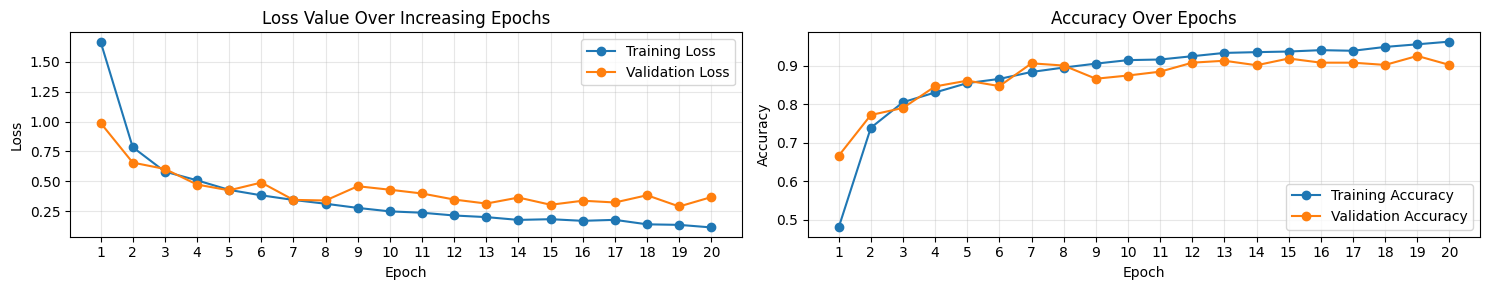

In [11]:
# Generate epoch numbers
epochs = np.arange(epoch_number) + 1

plt.figure(figsize=(15, 3))

# Loss graph
plt.subplot(121)

plt.title("Loss Value Over Increasing Epochs")

plt.plot(
    epochs,
    train_losses,
    marker='o',
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker='o',
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.xticks(epochs)

plt.legend()
plt.grid(alpha=0.3)


# Accuracy graph
plt.subplot(122)

plt.title("Accuracy Over Epochs")

plt.plot(
    epochs,
    train_accuracies,
    marker='o',
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracies,
    marker='o',
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.xticks(epochs)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

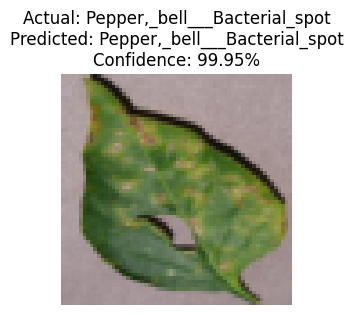

In [12]:
# Load the best model saved during training
model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Get one image from the test dataset
test_img, label = test_data[2]

# Add batch dimension and move image to device
img = test_img.unsqueeze(0).to(device)

# Predict image class
with torch.no_grad():

    output = model(img)

    # Convert logits to probabilities
    pred = torch.softmax(output, dim=1)

    # Get confidence and predicted class
    confidence, index = pred.max(-1)

# Display prediction
plt.figure(figsize=(3, 3))

plt.imshow(test_img.permute(1, 2, 0))

plt.title(
    f"Actual: {train_data.classes[label]}\n"
    f"Predicted: {train_data.classes[index.item()]}\n"
    f"Confidence: {confidence.item()*100:.2f}%"
)

plt.axis("off")
plt.show()

In [13]:
# Evaluate the best model on the independent test dataset
test_loss, test_acc = validation(
    test_dl,
    model,
    loss_fn
)

print(
    f"Test Loss: {test_loss:.4f}"
    f" | Test Accuracy: {test_acc*100:.2f}%"
)

Test Loss: 0.2337 | Test Accuracy: 92.00%


In [14]:
# Collect actual and predicted labels
actual_labels = []
predicted_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_dl:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        actual_labels.extend(labels.numpy())

        predicted_labels.extend(
            predictions.cpu().numpy()
        )

# Generate classification report
print("Classification Report")

print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=train_data.classes,
        digits=4,
        zero_division=0
    )
)

Classification Report
                                            precision    recall  f1-score   support

                        Apple___Apple_scab     0.9231    0.8000    0.8571        60
                         Apple___Black_rot     0.9206    0.9667    0.9431        60
                           Apple___healthy     0.9615    0.8333    0.8929        60
                 Background_without_leaves     0.9344    0.9500    0.9421        60
                       Blueberry___healthy     0.9091    1.0000    0.9524        60
                   Cherry___Powdery_mildew     0.9286    0.8667    0.8966        60
                          Cherry___healthy     0.9375    1.0000    0.9677        60
Corn___Cercospora_leaf_spot Gray_leaf_spot     0.8889    0.8000    0.8421        60
                        Corn___Common_rust     0.9672    0.9833    0.9752        60
               Corn___Northern_Leaf_Blight     0.8438    0.9000    0.8710        60
                            Corn___healthy     0.9833

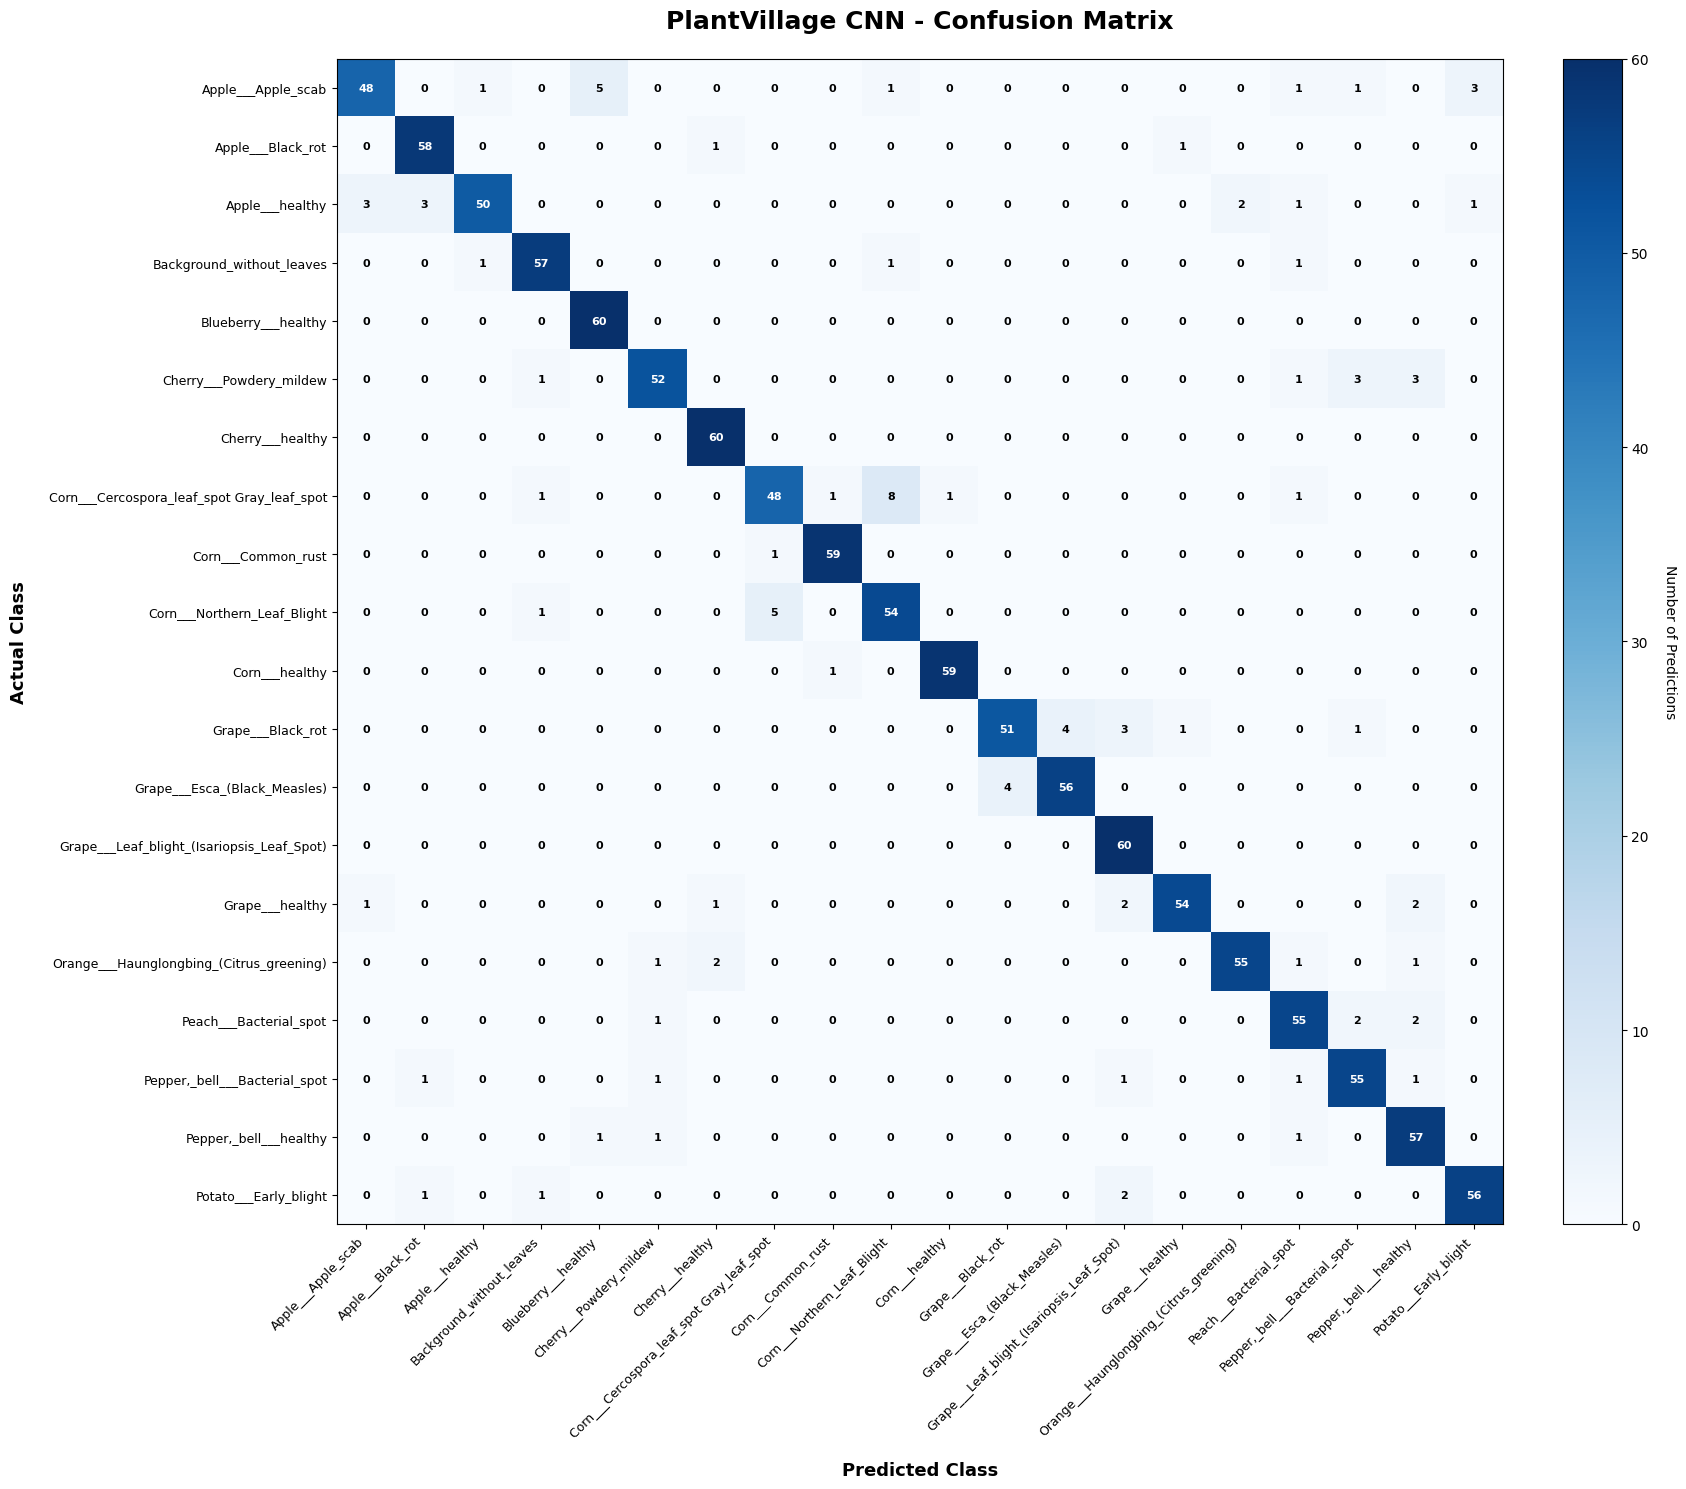

In [16]:
# Calculate confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=np.arange(20)
)

# Create figure
fig, ax = plt.subplots(figsize=(18, 15))

# Display confusion matrix
im = ax.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

# Add colorbar
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_ylabel("Number of Predictions", rotation=270, labelpad=20)

# Set class labels
classes = train_data.classes
tick_marks = np.arange(len(classes))

ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)

ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(classes, fontsize=9)

# Add numerical values inside each cell
threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8,
            fontweight="bold"
        )

# Titles and labels
ax.set_title(
    "PlantVillage CNN - Confusion Matrix",
    fontsize=18,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=13,
    fontweight="bold",
    labelpad=15
)

ax.set_ylabel(
    "Actual Class",
    fontsize=13,
    fontweight="bold",
    labelpad=15
)

# Improve layout
plt.tight_layout()

plt.show()

In [17]:
# Save the best trained model
final_model_path = "/content/PlantVillage_CNN.pth"

torch.save(
    model.state_dict(),
    final_model_path
)

print("Model saved successfully!")

print("Model location:", final_model_path)

# Display model file size
file_size = os.path.getsize(final_model_path) / (1024 * 1024)

print(f"Model Size: {file_size:.2f} MB")

Model saved successfully!
Model location: /content/PlantVillage_CNN.pth
Model Size: 24.81 MB


In [18]:
import json

# Save class names and their corresponding indices
class_mapping = {
    str(i): name
    for i, name in enumerate(train_data.classes)
}

with open(
    "/content/PlantVillage_Class_Mapping.json",
    "w"
) as file:

    json.dump(class_mapping, file, indent=4)

print("Class mapping saved successfully!")

Class mapping saved successfully!
